In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300)
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


In [2]:
adata_a = sc.read('../adatas/iAstrocytes_SCREEN1_filtered.h5ad')
adata_a

AnnData object with n_obs × n_vars = 195306 × 36601
    obs: 'target_gene', 'guide_vector', 'sequencing_batch'

In [3]:
adata_n = sc.read('../adatas/iNeurons_SCREEN1_filtered.h5ad')
adata_n

AnnData object with n_obs × n_vars = 189348 × 36601
    obs: 'target_gene', 'guide_vector', 'sequencing_batch'

### histogram cell counts for each perturbation

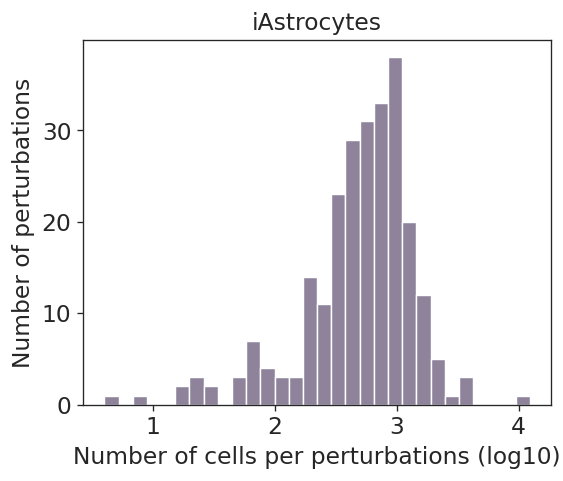

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# counts per gene, dropping INT
gene_counts = adata_a[adata_a.obs['target_gene'] != 'INT'].obs['target_gene'].value_counts()
gene_counts = np.log10(gene_counts)
# histogram

with sns.axes_style("ticks"):
    plt.figure(figsize=(5, 4))
    sns.histplot(gene_counts, bins=30, color='#685a7a')

    plt.xlabel("Number of cells per perturbations (log10)")
    plt.ylabel("Number of perturbations")
    plt.title("iAstrocytes")

    plt.savefig('figures/figS2_iAstrocytes_histogram_countsPerturbations.pdf')

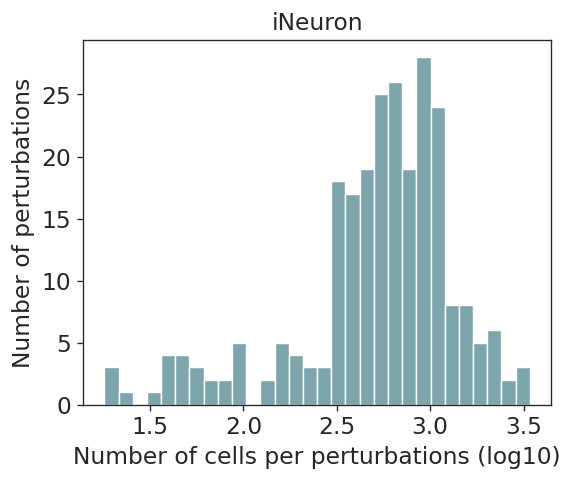

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# counts per gene, dropping INT
gene_counts = adata_n[adata_n.obs['target_gene'] != 'INT'].obs['target_gene'].value_counts()
gene_counts = np.log10(gene_counts)
# histogram

with sns.axes_style("ticks"):
    plt.figure(figsize=(5, 4))
    sns.histplot(gene_counts, bins=30, color='#508991')

    plt.xlabel("Number of cells per perturbations (log10)")
    plt.ylabel("Number of perturbations")
    plt.title("iNeuron")

    plt.savefig('figures/figS2_iNeurons_histogram_countsPerturbations.pdf')

### essential genes

In [6]:
essentials = pd.read_csv('/nfs/team361/so21/genesets/CRISPRInferredCommonEssentials.csv')
essentials = list(essentials['Essentials'].str.split(' ', expand=True)[0])

adata_a.obs['Essential'] = adata_a.obs.target_gene.isin(essentials)
adata_n.obs['Essential'] = adata_n.obs.target_gene.isin(essentials)

counts = pd.DataFrame(adata_a.obs.target_gene.value_counts())
counts.columns=['iAstrocytes']
counts['iNeurons'] = pd.DataFrame(adata_n.obs.target_gene.value_counts())
counts['Essential'] = counts.index.isin(essentials)
counts = counts.reset_index()

df_melted = counts.melt(id_vars=["target_gene", "Essential"], 
                    value_vars=["iAstrocytes", "iNeurons"],
                    var_name="CellType", value_name="Expression")

/tmp/ipykernel_167255/2040250877.py:13: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim((0, 32768))


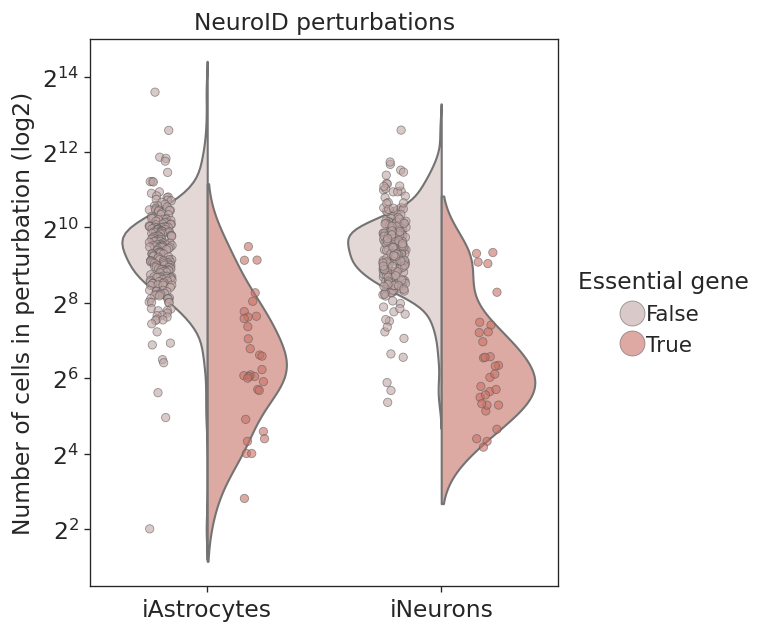

In [7]:
# violin plot

with sns.axes_style("ticks"):
    plt.figure(figsize=(5,6))
    sns.violinplot(data=df_melted, x="CellType", y="Expression", hue="Essential", split=True, log_scale=2, 
                   palette=['#e6d6d5', '#e6a29a'], legend=False, inner=None,  
                  )
    sns.stripplot(data=df_melted, x="CellType", y="Expression", hue="Essential", log_scale=2,
                  dodge=True, alpha=0.6, linewidth=0.5, legend=True,
                  palette=['#c0a5a4','#C97064']
                 )
    plt.title("NeuroID perturbations")
    plt.ylim((0, 32768))
    plt.ylabel("Number of cells in perturbation (log2)")
    plt.xlabel("")
    #plt.legend(title="Essential gene", frameon=False)
    handles, labels = plt.gca().get_legend_handles_labels()
    legend = plt.legend(
        handles[:2], labels[:2],
        title="Essential gene",
        frameon=False,
        loc='center left',
        bbox_to_anchor=(1, 0.5),
        markerscale=3
    )
    #plt.tight_layout()
    plt.savefig('figures/figS2_violin_essentialGenes.pdf', bbox_inches='tight')

### # of DEGs for cells

In [8]:
adata_counts = adata_n.copy()

print (adata_counts.X.shape)
print (adata_counts.obs.sequencing_batch.value_counts())
adata_counts = adata_counts[adata_counts.obs.sequencing_batch!='SCREEN1_2'].copy()
print (adata_counts.X.shape)
print (adata_counts.obs.sequencing_batch.value_counts())

import decoupler as dc

pdata_iN = dc.pp.pseudobulk(adata_counts,
                         sample_col="sequencing_batch", 
                         groups_col="target_gene",
                         layer=None,
                         mode="sum",
                        )

(189348, 36601)
sequencing_batch
SCREEN1_4    67911
SCREEN1_3    61038
SCREEN1_1    33487
SCREEN1_0    23729
SCREEN1_2     3183
Name: count, dtype: int64
(186165, 36601)
sequencing_batch
SCREEN1_4    67911
SCREEN1_3    61038
SCREEN1_1    33487
SCREEN1_0    23729
Name: count, dtype: int64


/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
pdata_iN.write('../adatas/pseudobulk_iNeurons2.h5ad')

In [9]:
pdata_iA = sc.read('../adatas/pseudobulk_iAstrocytes.h5ad')
pdata_iA

#pdata_iN = sc.read('../adatas/pseudobulk_iNeurons.h5ad')
#pdata_iN

iA_nDEGs_df = pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"),index_col=0)
iN_nDEGs_df = pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_sig_nDEGs.csv"),index_col=0)

pdata_iA_df1 = pdata_iA.obs.groupby('target_gene')['psbulk_cells'].sum()
pdata_iA_df2 = pdata_iA.obs.groupby('target_gene')['psbulk_counts'].sum()
pdata_iA_df = pd.DataFrame([pdata_iA_df1,pdata_iA_df2 ]).T
pdata_iA_df = iA_nDEGs_df.merge(pdata_iA_df, right_index=True, left_index=True)

pdata_iN_df1 = pdata_iN.obs.groupby('target_gene')['psbulk_cells'].sum()
pdata_iN_df2 = pdata_iN.obs.groupby('target_gene')['psbulk_counts'].sum()
pdata_iN_df = pd.DataFrame([pdata_iN_df1,pdata_iN_df2 ]).T
pdata_iN_df = iN_nDEGs_df.merge(pdata_iN_df, right_index=True, left_index=True)

2026-07-07 10:23:55 | [INFO] maxp pruned
2026-07-07 10:23:55 | [INFO] cmap pruned
2026-07-07 10:23:55 | [INFO] kern dropped
2026-07-07 10:23:55 | [INFO] post pruned
2026-07-07 10:23:55 | [INFO] FFTM dropped
2026-07-07 10:23:55 | [INFO] GPOS pruned
2026-07-07 10:23:55 | [INFO] GSUB pruned
2026-07-07 10:23:55 | [INFO] glyf pruned
2026-07-07 10:23:55 | [INFO] Added gid0 to subset
2026-07-07 10:23:55 | [INFO] Added first four glyphs to subset
2026-07-07 10:23:55 | [INFO] Closing glyph list over 'MATH': 32 glyphs before
2026-07-07 10:23:55 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'D', 'E', 'G', 'N', 'c', 'e', 'eight', 'f', 'five', 'four', 'g', 'i', 'l', 'nonmarkingreturn', 'o', 'one', 'parenleft', 'parenright', 'period', 'plus', 'r', 's', 'seven', 'six', 'space', 't', 'two', 'y', 'zero']
2026-07-07 10:23:55 | [INFO] Glyph IDs:   [0, 1, 2, 3, 11, 12, 14, 17, 19, 20, 21, 23, 24, 25, 26, 27, 36, 39, 40, 42, 49, 70, 72, 73, 74, 76, 79, 82, 85, 86, 87, 92]
2026-07-07 10:23:55 | [INFO] Clo

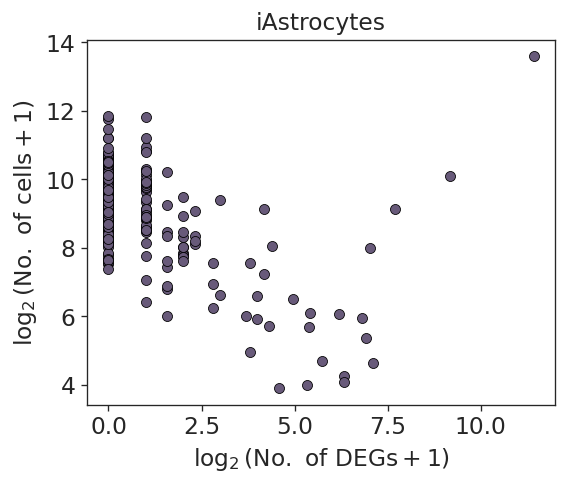

In [10]:
x = np.log2(pdata_iA_df['nDEGs']+1)
y = np.log2(pdata_iA_df['psbulk_cells']+1)

with sns.axes_style("ticks"):
    plt.figure(figsize=(5,4))
    sns.scatterplot(x=x,
                    y=y,
                    color=['#685a7a'], edgecolor='black'
                   )
    plt.title('iAstrocytes')
    plt.ylabel(r'$\log_2(\mathrm{No.\ of\ cells} + 1)$')
    plt.xlabel(r'$\log_2(\mathrm{No.\ of\ DEGs} + 1)$')
    plt.savefig('figures/figS2_number_DEGs_iAstrocytes.pdf', dpi=300, bbox_inches='tight')

2026-07-07 10:23:55 | [INFO] maxp pruned
2026-07-07 10:23:55 | [INFO] cmap pruned
2026-07-07 10:23:55 | [INFO] kern dropped
2026-07-07 10:23:55 | [INFO] post pruned
2026-07-07 10:23:55 | [INFO] FFTM dropped
2026-07-07 10:23:55 | [INFO] GPOS pruned
2026-07-07 10:23:55 | [INFO] GSUB pruned
2026-07-07 10:23:55 | [INFO] glyf pruned
2026-07-07 10:23:55 | [INFO] Added gid0 to subset
2026-07-07 10:23:55 | [INFO] Added first four glyphs to subset
2026-07-07 10:23:55 | [INFO] Closing glyph list over 'MATH': 29 glyphs before
2026-07-07 10:23:55 | [INFO] Glyph names: ['.notdef', '.null', 'D', 'E', 'G', 'N', 'c', 'e', 'eight', 'f', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'parenleft', 'parenright', 'period', 'plus', 'r', 's', 'six', 'space', 'two', 'u', 'zero']
2026-07-07 10:23:55 | [INFO] Glyph IDs:   [0, 1, 2, 3, 11, 12, 14, 17, 19, 20, 21, 23, 25, 27, 39, 40, 42, 49, 70, 72, 73, 74, 76, 79, 81, 82, 85, 86, 88]
2026-07-07 10:23:55 | [INFO] Closed glyph list over 'MATH': 35 gly

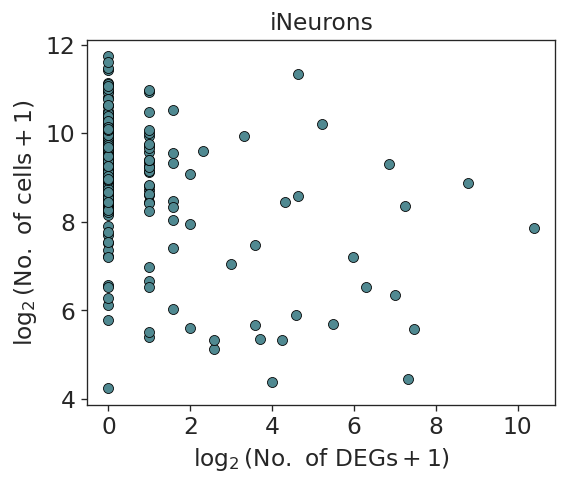

In [11]:
x = np.log2(pdata_iN_df['nDEGs']+1)
y = np.log2(pdata_iN_df['psbulk_cells']+1)

with sns.axes_style("ticks"):
    plt.figure(figsize=(5,4))
    sns.scatterplot(x=x,
                    y=y,
                    color=['#508991'], edgecolor='black'
                   )
    plt.title('iNeurons')
    plt.ylabel(r'$\log_2(\mathrm{No.\ of\ cells} + 1)$')
    plt.xlabel(r'$\log_2(\mathrm{No.\ of\ DEGs} + 1)$')
    plt.savefig('figures/figS2_number_DEGs_iNeurons.pdf', dpi=300, bbox_inches='tight')

2026-07-07 10:23:56 | [INFO] maxp pruned
2026-07-07 10:23:56 | [INFO] cmap pruned
2026-07-07 10:23:56 | [INFO] kern dropped
2026-07-07 10:23:56 | [INFO] post pruned
2026-07-07 10:23:56 | [INFO] FFTM dropped
2026-07-07 10:23:56 | [INFO] GPOS pruned
2026-07-07 10:23:56 | [INFO] GSUB pruned
2026-07-07 10:23:56 | [INFO] glyf pruned
2026-07-07 10:23:56 | [INFO] Added gid0 to subset
2026-07-07 10:23:56 | [INFO] Added first four glyphs to subset
2026-07-07 10:23:56 | [INFO] Closing glyph list over 'MATH': 32 glyphs before
2026-07-07 10:23:56 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'D', 'E', 'G', 'N', 'c', 'e', 'eight', 'f', 'five', 'four', 'g', 'i', 'l', 'nonmarkingreturn', 'o', 'one', 'parenleft', 'parenright', 'period', 'plus', 'r', 's', 'seven', 'six', 'space', 't', 'two', 'y', 'zero']
2026-07-07 10:23:56 | [INFO] Glyph IDs:   [0, 1, 2, 3, 11, 12, 14, 17, 19, 20, 21, 23, 24, 25, 26, 27, 36, 39, 40, 42, 49, 70, 72, 73, 74, 76, 79, 82, 85, 86, 87, 92]
2026-07-07 10:23:56 | [INFO] Clo

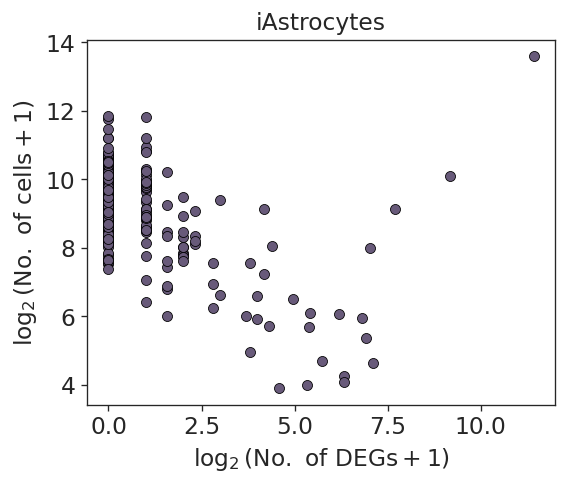

In [12]:
x = np.log2(pdata_iA_df['nDEGs']+1)
y = np.log2(pdata_iA_df['psbulk_cells']+1)

with sns.axes_style("ticks"):
    plt.figure(figsize=(5,4))
    sns.scatterplot(x=x,
                    y=y,
                    color=['#685a7a'], edgecolor='black'
                   )
    plt.title('iAstrocytes')
    plt.ylabel(r'$\log_2(\mathrm{No.\ of\ cells} + 1)$')
    plt.xlabel(r'$\log_2(\mathrm{No.\ of\ DEGs} + 1)$')
    plt.savefig('figures/figS2_number_DEGs_iAstrocytes.pdf', dpi=300, bbox_inches='tight')

2026-07-07 10:23:57 | [INFO] maxp pruned
2026-07-07 10:23:57 | [INFO] cmap pruned
2026-07-07 10:23:57 | [INFO] kern dropped
2026-07-07 10:23:57 | [INFO] post pruned
2026-07-07 10:23:57 | [INFO] FFTM dropped
2026-07-07 10:23:57 | [INFO] GPOS pruned
2026-07-07 10:23:57 | [INFO] GSUB pruned
2026-07-07 10:23:57 | [INFO] glyf pruned
2026-07-07 10:23:57 | [INFO] Added gid0 to subset
2026-07-07 10:23:57 | [INFO] Added first four glyphs to subset
2026-07-07 10:23:57 | [INFO] Closing glyph list over 'MATH': 29 glyphs before
2026-07-07 10:23:57 | [INFO] Glyph names: ['.notdef', '.null', 'D', 'E', 'G', 'N', 'c', 'e', 'eight', 'f', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'parenleft', 'parenright', 'period', 'plus', 'r', 's', 'six', 'space', 'two', 'u', 'zero']
2026-07-07 10:23:57 | [INFO] Glyph IDs:   [0, 1, 2, 3, 11, 12, 14, 17, 19, 20, 21, 23, 25, 27, 39, 40, 42, 49, 70, 72, 73, 74, 76, 79, 81, 82, 85, 86, 88]
2026-07-07 10:23:57 | [INFO] Closed glyph list over 'MATH': 35 gly

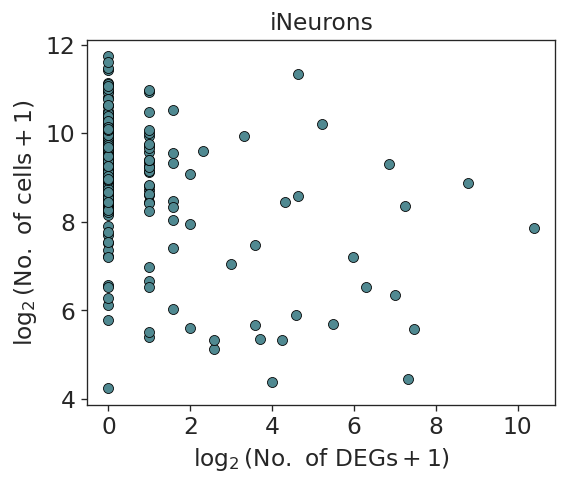

In [13]:
x = np.log2(pdata_iN_df['nDEGs']+1)
y = np.log2(pdata_iN_df['psbulk_cells']+1)

with sns.axes_style("ticks"):
    plt.figure(figsize=(5,4))
    sns.scatterplot(x=x,
                    y=y,
                    color=['#508991'], edgecolor='black'
                   )
    plt.title('iNeurons')
    plt.ylabel(r'$\log_2(\mathrm{No.\ of\ cells} + 1)$')
    plt.xlabel(r'$\log_2(\mathrm{No.\ of\ DEGs} + 1)$')
    plt.savefig('figures/figS2_number_DEGs_iNeurons.pdf', dpi=300, bbox_inches='tight')

### GSVA

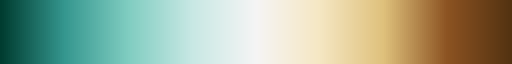

In [14]:
from matplotlib.colors import LinearSegmentedColormap

palette = [
    "#533211",
    "#8c5322",
    "#dfc17c",
    "#f5e7c3",
    "#f5f5f5",
    "#c8e8e4",
    "#80cdc1",
    "#35978f",
    #"#03675e",
    "#003c30"
]
palette= palette[::-1]

cmap = LinearSegmentedColormap.from_list("brown_teal", palette)
cmap

In [15]:
iA_up = iA_nDEGs_df[iA_nDEGs_df['nDEGs_up_lfc'] >= 5].index # get perturbations with >5 up-regulated genes @ lfc>0.25
iA_down = iA_nDEGs_df[iA_nDEGs_df['nDEGs_down_lfc'] >= 5].index
iN_up = iN_nDEGs_df[iN_nDEGs_df['nDEGs_up_lfc'] >= 5].index # get perturbations with >5 up-regulated genes @ lfc>0.25
iN_down = iN_nDEGs_df[iN_nDEGs_df['nDEGs_down_lfc'] >= 5].index

import pickle
with open("../DEGs/pyDESeq2/iA_DEGs_sig.pkl", "rb") as f:
    iA_DEGs_sig_dict = pickle.load(f)

with open("../DEGs/pyDESeq2/iN_DEGs_sig.pkl", "rb") as f:
    iN_DEGs_sig_dict = pickle.load(f)

2026-07-07 10:24:06 | [INFO] maxp pruned
2026-07-07 10:24:06 | [INFO] cmap pruned
2026-07-07 10:24:06 | [INFO] kern dropped
2026-07-07 10:24:06 | [INFO] post pruned
2026-07-07 10:24:06 | [INFO] FFTM dropped
2026-07-07 10:24:06 | [INFO] GPOS pruned
2026-07-07 10:24:06 | [INFO] GSUB pruned
2026-07-07 10:24:06 | [INFO] glyf pruned
2026-07-07 10:24:06 | [INFO] Added gid0 to subset
2026-07-07 10:24:06 | [INFO] Added first four glyphs to subset
2026-07-07 10:24:06 | [INFO] Closing glyph list over 'MATH': 41 glyphs before
2026-07-07 10:24:06 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'Y', 'e', 'eight', 'five', 'm', 'minus', 'nine', 'nonmarkingreturn', 'one', 'period', 'r', 'seven', 'six', 'space', 't', 'three', 'two', 'underscore', 'zero']
2026-07-07 10:24:06 | [INFO] Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 22, 24, 25, 26, 27, 28, 36, 37, 38, 39, 40, 41, 42, 43, 44, 46, 47, 48, 49, 50, 51, 53

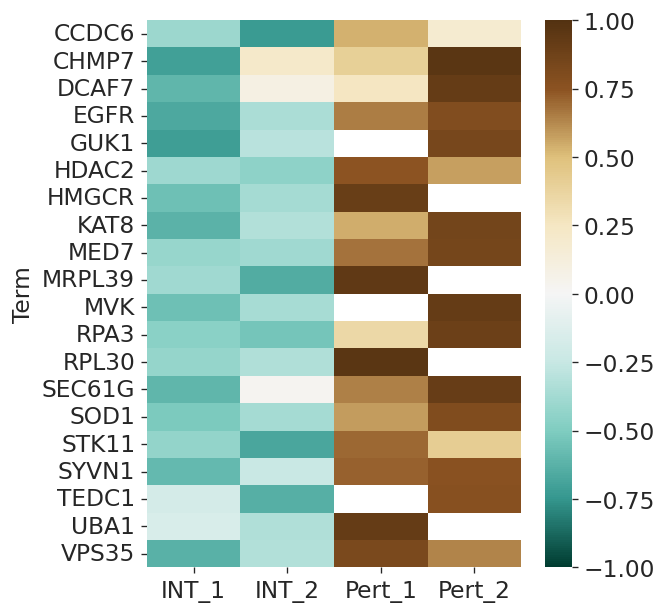

In [16]:
### iAstrocytes
target_dict = {key: list(value[value.log_fc > 0]['variable']) for key, value in iA_DEGs_sig_dict.items() if key in iA_up}

test_pdata = pdata_iA[pdata_iA.obs.target_gene.isin(['INT'] + list(iA_up))].copy()
sc.pp.normalize_total(test_pdata, target_sum=1e6)
sc.pp.log1p(test_pdata)
expr_df = pd.DataFrame(test_pdata.X.T, index=test_pdata.var_names, columns=test_pdata.obs_names)

import gseapy as gp
gsva_res = gp.gsva(
        data=expr_df,
        gene_sets=target_dict,
        method='gsva',
        max_size=2000,
        outdir=None,
        no_plot=True
    )

#collect results
pivot_df = gsva_res.res2d.pivot_table(
    index="Term",       # rows
    columns="Name",     # columns
    values="ES",        # values to fill
    aggfunc="first"     # in case duplicates exist
)

gsva_result_df = pivot_df.astype(float)
final_res = pd.DataFrame(index=gsva_result_df.index,
                         columns=['INT_1','INT_2','Pert_1','Pert_2'])

for pert in final_res.index:
    row = gsva_result_df.loc[pert]  # one row as Series

    final_res.loc[pert, 'INT_1']  = row.get('SCREEN1_1_INT',  np.nan)
    final_res.loc[pert, 'INT_2']  = row.get('SCREEN1_2_INT',  np.nan)
    final_res.loc[pert, 'Pert_1'] = row.get(f'SCREEN1_1_{pert}', np.nan)
    final_res.loc[pert, 'Pert_2'] = row.get(f'SCREEN1_2_{pert}', np.nan)
    
with sns.axes_style('ticks'):
    plt.figure(figsize=(5,6))
    sns.heatmap(final_res.astype(float), vmax=1, vmin=-1,center=0, cmap=cmap)
    plt.savefig('figures/gsva_iA_up.pdf', dpi=300)

2026-07-07 10:24:15 | [INFO] maxp pruned
2026-07-07 10:24:15 | [INFO] cmap pruned
2026-07-07 10:24:15 | [INFO] kern dropped
2026-07-07 10:24:15 | [INFO] post pruned
2026-07-07 10:24:15 | [INFO] FFTM dropped
2026-07-07 10:24:15 | [INFO] GPOS pruned
2026-07-07 10:24:16 | [INFO] GSUB pruned
2026-07-07 10:24:16 | [INFO] glyf pruned
2026-07-07 10:24:16 | [INFO] Added gid0 to subset
2026-07-07 10:24:16 | [INFO] Added first four glyphs to subset
2026-07-07 10:24:16 | [INFO] Closing glyph list over 'MATH': 41 glyphs before
2026-07-07 10:24:16 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'Y', 'e', 'eight', 'five', 'm', 'minus', 'nine', 'nonmarkingreturn', 'one', 'period', 'r', 'seven', 'six', 'space', 't', 'three', 'two', 'underscore', 'zero']
2026-07-07 10:24:16 | [INFO] Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 22, 24, 25, 26, 27, 28, 36, 37, 38, 39, 40, 41, 42, 43, 44, 46, 47, 48, 49, 50, 51, 53

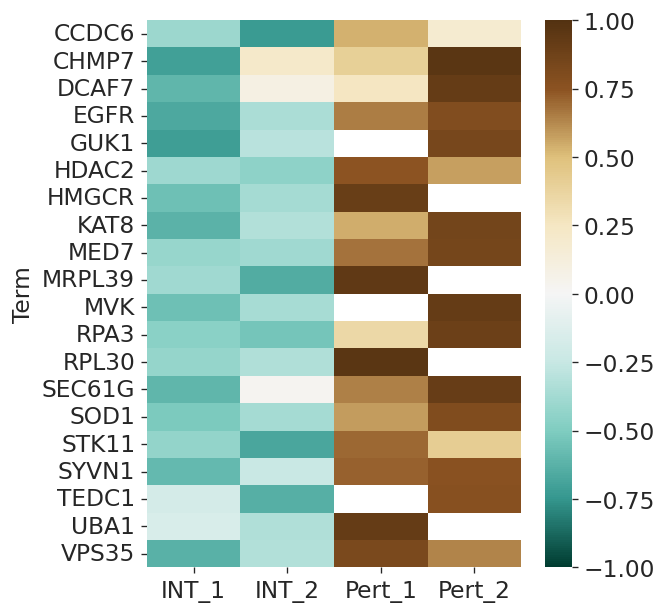

In [17]:
### iAstrocytes
target_dict = {key: list(value[value.log_fc > 0]['variable']) for key, value in iA_DEGs_sig_dict.items() if key in iA_up}

test_pdata = pdata_iA[pdata_iA.obs.target_gene.isin(['INT'] + list(iA_up))].copy()
sc.pp.normalize_total(test_pdata, target_sum=1e6)
sc.pp.log1p(test_pdata)
expr_df = pd.DataFrame(test_pdata.X.T, index=test_pdata.var_names, columns=test_pdata.obs_names)

import gseapy as gp
gsva_res = gp.gsva(
        data=expr_df,
        gene_sets=target_dict,
        method='gsva',
        max_size=2000,
        outdir=None,
        no_plot=True
    )

#collect results
pivot_df = gsva_res.res2d.pivot_table(
    index="Term",       # rows
    columns="Name",     # columns
    values="ES",        # values to fill
    aggfunc="first"     # in case duplicates exist
)

gsva_result_df = pivot_df.astype(float)
final_res = pd.DataFrame(index=gsva_result_df.index,
                         columns=['INT_1','INT_2','Pert_1','Pert_2'])

for pert in final_res.index:
    row = gsva_result_df.loc[pert]  # one row as Series

    final_res.loc[pert, 'INT_1']  = row.get('SCREEN1_1_INT',  np.nan)
    final_res.loc[pert, 'INT_2']  = row.get('SCREEN1_2_INT',  np.nan)
    final_res.loc[pert, 'Pert_1'] = row.get(f'SCREEN1_1_{pert}', np.nan)
    final_res.loc[pert, 'Pert_2'] = row.get(f'SCREEN1_2_{pert}', np.nan)
    
with sns.axes_style('ticks'):
    plt.figure(figsize=(5,6))
    sns.heatmap(final_res.astype(float), vmax=1, vmin=-1,center=0, cmap=cmap)
    plt.savefig('figures/gsva_iA_up.pdf', dpi=300)

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
  return fn(*args_all, **kw)
2026-07-07 10:24:31 | [INFO] maxp pruned
2026-07-07 10:24:31 | [INFO] cmap pruned
2026-07-07 10:24:31 | [INFO] kern dropped
2026-07-07 10:24:31 | [INFO] post pruned
2026-07-07 10:24:31 | [INFO] FFTM dropped
2026-07-07 10:24:31 | [INFO] GPOS pruned
2026-07-07 10:24:31 | [INFO] GSUB pruned
2026-07-07 10:24:31 | [INFO] glyf pruned
2026-07-07 10:24:31 | [INFO] Added gid0 to subset
2026-07-07 10:24:31 | [INFO] Added first four glyphs to subset
2026-07-07 10:24:31 | [INFO] Closing glyph list over 'MATH': 41 glyphs before
2026-07-07 10:24:31 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'H', 'I', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'W', 'Y', 'e', 'f', 'five', 'four', 'm', 'minus', 'nine', 'nonmarkingreturn', 'o', 'one', 'period', 'r', 'seven', 'space', 't', 'three', 'two', 'undersc

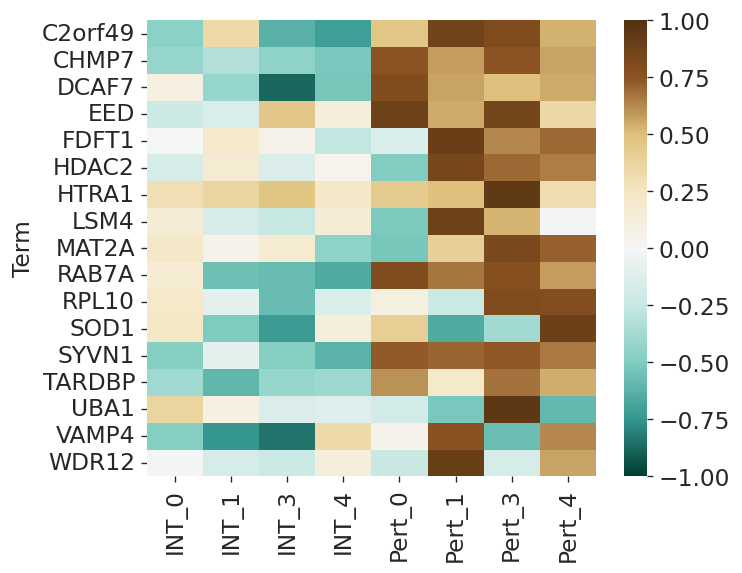

In [18]:
### iNeurons
target_dict = {key: list(value[value.log_fc > 0]['variable']) for key, value in iN_DEGs_sig_dict.items() if 
               key in iN_up}

test_pdata = pdata_iN[pdata_iN.obs.target_gene.isin(['INT'] + list(iN_up))].copy()
sc.pp.normalize_total(test_pdata, target_sum=1e6)
sc.pp.log1p(test_pdata)
expr_df = pd.DataFrame(test_pdata.X.T, index=test_pdata.var_names, columns=test_pdata.obs_names)

import gseapy as gp
gsva_res = gp.gsva(
        data=expr_df,
        gene_sets=target_dict,max_size=2000,
        method='gsva',
        outdir=None,
        no_plot=True
    )

#collect results
pivot_df = gsva_res.res2d.pivot_table(
    index="Term",       # rows
    columns="Name",     # columns
    values="ES",        # values to fill
    aggfunc="first"     # in case duplicates exist
)

gsva_result_df = pivot_df.astype(float)
final_res = pd.DataFrame(index=gsva_result_df.index,
                         columns=['INT_0','INT_1','INT_3','INT_4',
                                  'Pert_0','Pert_1','Pert_3','Pert_4'
                                 ])

for pert in final_res.index:
    row = gsva_result_df.loc[pert]  # one row as Series

    final_res.loc[pert, 'INT_0']  = row.get('SCREEN1_0_INT',  np.nan)
    final_res.loc[pert, 'INT_1']  = row.get('SCREEN1_1_INT',  np.nan)
    #final_res.loc[pert, 'INT_2']  = row.get('SCREEN1_2_INT',  np.nan)
    final_res.loc[pert, 'INT_3']  = row.get('SCREEN1_3_INT',  np.nan)
    final_res.loc[pert, 'INT_4']  = row.get('SCREEN1_4_INT',  np.nan)
    final_res.loc[pert, 'Pert_0'] = row.get(f'SCREEN1_0_{pert}', np.nan)
    final_res.loc[pert, 'Pert_1'] = row.get(f'SCREEN1_1_{pert}', np.nan)
    #final_res.loc[pert, 'Pert_2'] = row.get(f'SCREEN1_2_{pert}', np.nan)
    final_res.loc[pert, 'Pert_3'] = row.get(f'SCREEN1_3_{pert}', np.nan)
    final_res.loc[pert, 'Pert_4'] = row.get(f'SCREEN1_4_{pert}', np.nan)

with sns.axes_style('ticks'):
    plt.figure(figsize=(6,5))
    sns.heatmap(final_res.astype(float), vmax=1, vmin=-1, center=0, cmap=cmap)
    plt.savefig('figures/gsva_iN_up.pdf', dpi=300)

In [20]:
adata_n.obs.sequencing_batch.value_counts()

sequencing_batch
SCREEN1_4    67911
SCREEN1_3    61038
SCREEN1_1    33487
SCREEN1_0    23729
SCREEN1_2     3183
Name: count, dtype: int64

### GO for perturbation results